In [63]:
import numpy as np
import matplotlib.pyplot as plt
import random

Exam 1 - ALi khabazian
Question 6

In [64]:
data = np.loadtxt("C:\\Users\\user\\OneDrive\\Desktop\\software\\GN512.txt")

(512, 512)


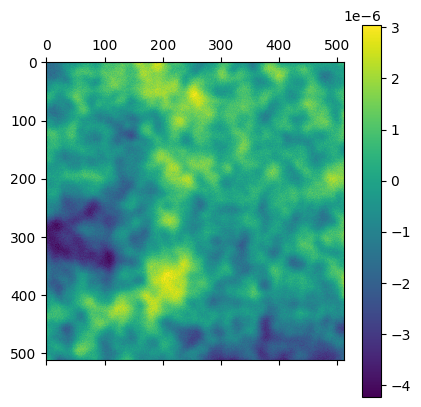

In [65]:
data_r=[]
for i in range(512):
    row=[]
    for j in range(512):
        row.append(random.random())
    data_r.append(row)
data_random=np.array(data_r)

print(np.shape(data))
plt.matshow(data)
plt.colorbar()


(512, 512)


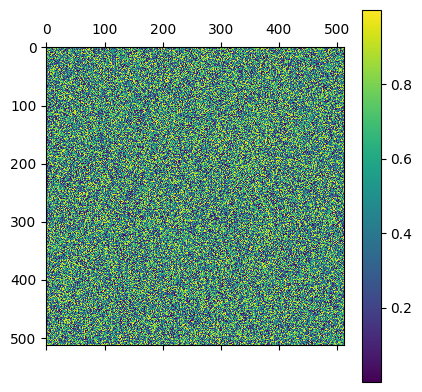

In [66]:
print(np.shape(data_random))
plt.matshow(data_random)
plt.colorbar()


In [67]:
x = data[:, 0]
y = data[:, 1]
v = data[:, 2]

sigma = np.std(v)
peaks = np.where(v >= 0.5 * sigma)[0]
troughs = np.where(v <= -0.5 * sigma)[0]

In [68]:
def natural_estimator(data1, data2, r_max, n_bins):
    r = np.linspace(0, r_max, n_bins)
    dr = r[1] - r[0]
    
    tpcf = np.zeros_like(r)
    
    for i in range(len(data1)):
        for j in range(len(data2)):
            dx = data1[i, 0] - data2[j, 0]
            dy = data1[i, 1] - data2[j, 1]
            rij = np.sqrt(dx**2 + dy**2)
            
            bin_idx = int(rij // dr)
            if bin_idx < n_bins:
                tpcf[bin_idx] += 1
    
    norm = len(data1) * len(data2) * np.pi * ((2 * r + dr)**2 - (2 * r - dr)**2)
    tpcf /= norm
    
    return r, tpcf

r_max = np.max(np.sqrt(x**2 + y**2))
n_bins = 100
r, tpcf = natural_estimator(np.column_stack((x[peaks], y[peaks])), np.column_stack((x[troughs], y[troughs])), r_max, n_bins)

C:\Users\user\AppData\Local\Temp\ipykernel_12076\131518070.py:18: RuntimeWarning: invalid value encountered in divide
  tpcf /= norm


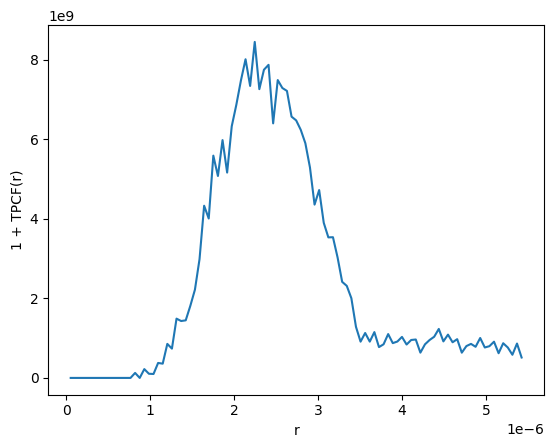

In [69]:
import matplotlib.pyplot as plt
plt.plot(r, 1 + tpcf)
plt.xlabel('r')
plt.ylabel('1 + TPCF(r)')
plt.show()


In [70]:
epsilon = 0.01
r_ex = r[np.argmax(1 + tpcf >= 1 + epsilon)]
print(f"The radius of the exclusion zone (R_ex) is: {r_ex}")

The radius of the exclusion zone (R_ex) is: 8.220629610120586e-07


In [72]:
def peak(data,alpha):
    dx=1
    
    x,y=np.shape(data)
    N_peak=0
    y_list=[]
    peak_pos_x=[]
    peak_pos_y=[]
    peak_pos_dot=[]
                        
    for i in range(2,x-1):
        for j in range(2,y-1):
            if data[i][j]>alpha :
                
                r1=(data[i][j]-data[i-1][j])/dx
                r2=(data[i][j]-data[i+1][j])/dx
                r3=(data[i][j]-data[i][j-1])/dx
                r4=(data[i][j]-data[i][j+1])/dx
                r5=(data[i][j]-data[i+1][j+1])/dx
                r6=(data[i][j]-data[i-1][j+1])/dx
                r7=(data[i][j]-data[i+1][j-1])/dx
                r8=(data[i][j]-data[i-1][j-1])/dx

                if r1>0 and r2>0 and r3>0 and r4>0 and r5>0 and r6>0 and r7>0 and r8>0 :
                    N_peak=N_peak+1
                    y_list.append(data[i][j])
                    peak_pos_x.append(j)
                    peak_pos_y.append(i)
                    peak_pos_dot.append([j,i])        

    dR=1
    m=int((x*np.sqrt(2))/dR)+1
    pdf=np.zeros(m)
    
    for i in range(1,N_peak-1):
        for j in range(i+1,N_peak):
            R=int(np.sqrt(((peak_pos_dot[i][0]-peak_pos_dot[j][0])**2+(peak_pos_dot[i][1]-peak_pos_dot[j][1])**2))/dR)+1
            pdf[R-1]=pdf[R-1]+1
            
    pdf_new=np.array(pdf)/sum(pdf)
    
    return N_peak , pdf_new , peak_pos_x , peak_pos_y

12648


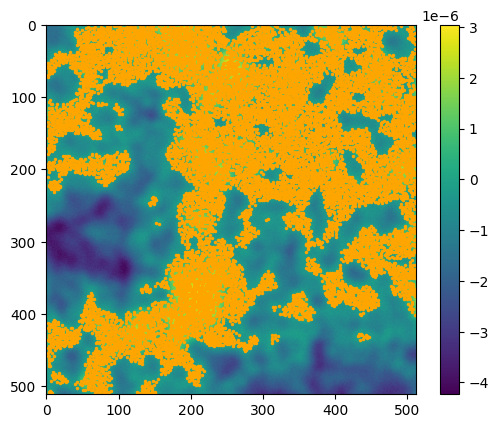

In [73]:

N_peak_data1 , pdf1 , peak_pos_x_data1 , peak_pos_y_data1  = peak(data, np.var(data)*0.5)
plt.imshow(data)
plt.colorbar()
plt.plot(peak_pos_x_data1, peak_pos_y_data1,'.',markersize=3 ,color='orange')
print(len(peak_pos_x_data1))

In [74]:
def peak_random(pdf,N_peak):
    peak_list_random=[]
    N_peak_random=N_peak
    for i in range(1000):
        x=random.randrange(len(pdf))
        y=max(pdf)*random.random()

        if y<pdf[x] :
            peak_list_random.append(x)
    peak_list_random_n=np.array(peak_list_random)
    
    dx=1
    
    min_data = np.min(peak_list_random_n)
    max_data = np.max(peak_list_random_n)

    num_class = int((max_data - min_data)/dx) + 1

    pdf_random_new = np.zeros(num_class)

    peak_list_random_n = peak_list_random_n - min_data

    for i in range(len(peak_list_random_n)):
        t = int(peak_list_random_n[i]/dx)
        pdf_random_new[t] = pdf_random_new[t]+1  

    pdf_random_new = pdf_random_new / (np.sum(pdf_random_new)*dx) 
    
    return(N_peak_random,pdf_random_new)

Text(0.5, 1.0, 'pdf_peak_random_1')

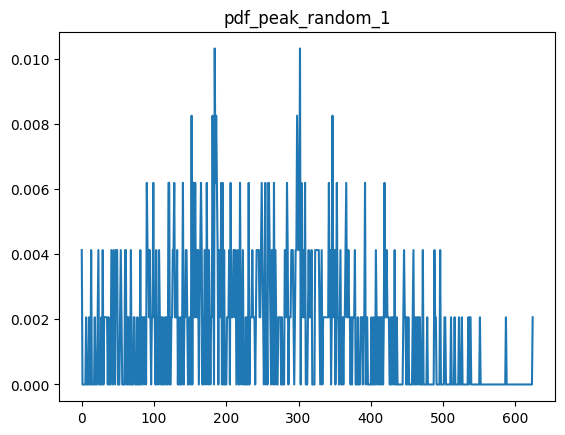

In [75]:
N_peak_random_1,pdf_random_1=peak_random(pdf1, N_peak_data1)

plt.plot(pdf_random_1)
plt.title('pdf_peak_random_1')


Text(0.5, 1.0, 'pdf_The distance between the peaks_data1')

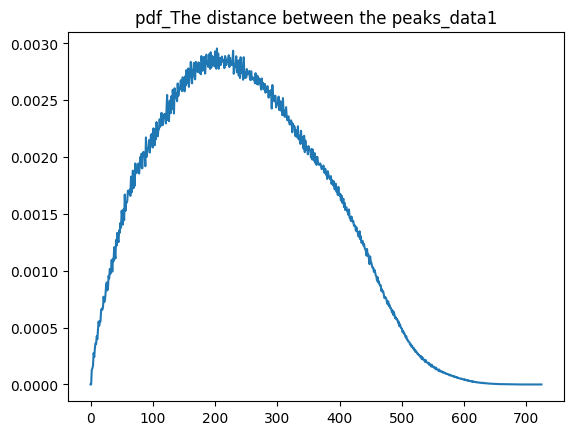

In [76]:

plt.plot(range(0,len(pdf1)),pdf1)
plt.title('pdf_The distance between the peaks_data1')